In [ ]:
import pandas as pd          # for working with tables
import numpy as np           # for numbers and random values
import matplotlib.pyplot as plt   # for charts

print("Ready.")

Ready.


In [ ]:
column_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty",
]

url = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"
data = pd.read_csv(url, header=None, names=column_names)

print("Number of rows:", len(data))
print("Number of columns:", len(data.columns))
data.head(3)

Number of rows: 125973
Number of columns: 43


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19


In [ ]:
data["attack"] = (data["label"] != "normal").astype(int)

print(data["attack"].value_counts())
print()
print("0 = normal, 1 = attack")

attack
0    67343
1    58630
Name: count, dtype: int64

0 = normal, 1 = attack


In [ ]:
random = np.random.default_rng(42)   # 42 keeps the results the same every time we run
n = len(data)
is_attack = data["attack"].to_numpy()

# --- warning sign 1: real data -----------------------------------------
data["failed_attempt"] = (data["num_failed_logins"] > 0).astype(int)

# --- a small helper: flip a coin for every row -------------------------
def coin_flip(chance_if_attack, chance_if_normal):
    chance = np.where(is_attack == 1, chance_if_attack, chance_if_normal)
    return (random.random(n) < chance).astype(int)

# --- warning signs 2, 3, 4: added by us --------------------------------
data["unusual_country"] = coin_flip(0.97, 0.04)   # 97% of attacks, 4% of normal logins
data["new_device"]      = coin_flip(0.92, 0.08)
data["odd_hour"]        = coin_flip(0.55, 0.13)

warning_signs = ["failed_attempt", "unusual_country", "new_device", "odd_hour"]

data[warning_signs + ["attack"]].head(10)

,failed_attempt,unusual_country,new_device,odd_hour,attack
0,0,0,0,0,0
1,0,0,0,1,0
2,0,1,1,1,1
3,0,0,0,0,0
4,0,0,0,0,0
5,0,0,1,1,1
6,0,1,1,0,1
7,0,1,1,0,1
8,0,1,1,0,1
9,0,1,1,1,1


In [ ]:
number_of_attacks = data["attack"].sum()
total_logins = len(data)

prior = number_of_attacks / total_logins

print("Attacks       :", number_of_attacks)
print("Total logins  :", total_logins)
print()
print("P(attack) =", round(prior, 4), "  that is about", round(prior * 100, 1), "%")

Attacks       : 58630
Total logins  : 125973

P(attack) = 0.4654   that is about 46.5 %


In [ ]:
# keep only rows where unusual_country is 1
rows = data[data["unusual_country"] == 1]

print("Logins from an unusual country :", len(rows))
print("How many of those were attacks :", rows["attack"].sum())
print()
print("P(attack | unusual country) =", round(rows["attack"].mean(), 4))
print()
print("Compare with the starting probability:", round(prior, 4))

Logins from an unusual country : 59529
How many of those were attacks : 56840

P(attack | unusual country) = 0.9548

Compare with the starting probability: 0.4654


In [ ]:
def chance_of_attack(**conditions):
    """Give it conditions, it returns the probability of attack and how many rows matched.

    Example:  chance_of_attack(new_device=1, odd_hour=1)
    """
    rows = data
    for column_name, value in conditions.items():
        rows = rows[rows[column_name] == value]

    if len(rows) == 0:
        return None, 0
    return rows["attack"].mean(), len(rows)


# try it out
p, how_many = chance_of_attack(new_device=1)
print("P(attack | new device) =", round(p, 4), "   based on", how_many, "logins")

p, how_many = chance_of_attack(new_device=0)
print("P(attack | NOT new device) =", round(p, 4), "   based on", how_many, "logins")

P(attack | new device) = 0.9096    based on 59227 logins
P(attack | NOT new device) = 0.0713    based on 66746 logins


In [ ]:
results = []

for sign in warning_signs:
    p_present, n_present = chance_of_attack(**{sign: 1})
    p_absent,  n_absent  = chance_of_attack(**{sign: 0})
    results.append({
        "warning sign": sign,
        "how many logins have it": n_present,
        "P(attack) if present": round(p_present, 4),
        "P(attack) if absent": round(p_absent, 4),
    })

table = pd.DataFrame(results)
print("Starting probability (no information):", round(prior, 4))
print()
table

Starting probability (no information): 0.4654



,warning sign,how many logins have it,P(attack) if present,P(attack) if absent
0,failed_attempt,122,0.4426,0.4654
1,unusual_country,59529,0.9548,0.0269
2,new_device,59227,0.9096,0.0713
3,odd_hour,41148,0.7856,0.3101


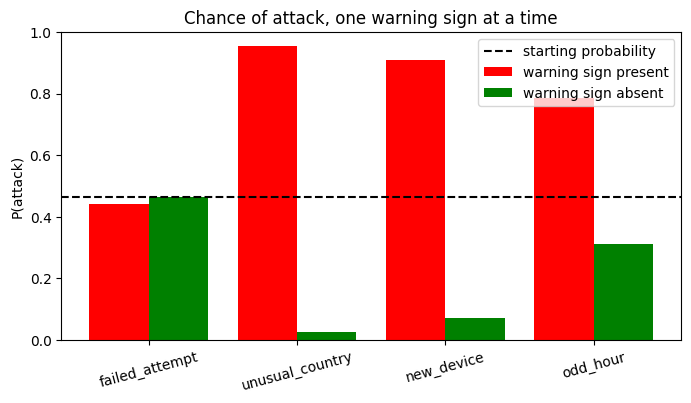

In [ ]:
plt.figure(figsize=(8, 4))

positions = np.arange(len(table))
plt.bar(positions - 0.2, table["P(attack) if present"], width=0.4,
        color="red", label="warning sign present")
plt.bar(positions + 0.2, table["P(attack) if absent"], width=0.4,
        color="green", label="warning sign absent")
plt.axhline(prior, color="black", linestyle="--", label="starting probability")

plt.xticks(positions, table["warning sign"], rotation=15)
plt.ylabel("P(attack)")
plt.title("Chance of attack, one warning sign at a time")
plt.legend()
plt.ylim(0, 1)
plt.show()

In [ ]:
evidence = "unusual_country"

# --- the three ingredients ---------------------------------------------
attacks_only = data[data["attack"] == 1]

P_E_given_A = attacks_only[evidence].mean()   # among attacks, how often is the sign present
P_A         = prior                           # starting probability
P_E         = data[evidence].mean()           # among all logins, how often is the sign present

# --- the formula --------------------------------------------------------
answer_by_formula = (P_E_given_A * P_A) / P_E

# --- the counting method from Step 6 ------------------------------------
answer_by_counting, _ = chance_of_attack(**{evidence: 1})

print("P(E | A) =", round(P_E_given_A, 4))
print("P(A)     =", round(P_A, 4))
print("P(E)     =", round(P_E, 4))
print()
print("Answer using Bayes' formula :", round(answer_by_formula, 6))
print("Answer by counting rows     :", round(answer_by_counting, 6))
print()
print("They match. Bayes' theorem and counting give the same result.")

P(E | A) = 0.9695
P(A)     = 0.4654
P(E)     = 0.4726

Answer using Bayes' formula : 0.954829
Answer by counting rows     : 0.954829

They match. Bayes' theorem and counting give the same result.


In [ ]:
p_all_four, n_all_four = chance_of_attack(failed_attempt=1, unusual_country=1,
                                          new_device=1, odd_hour=1)

print("Logins with ALL 4 warning signs:", n_all_four)
print("P(attack | all 4 warning signs) =", round(p_all_four, 4))
print()

p_none, n_none = chance_of_attack(failed_attempt=0, unusual_country=0,
                                  new_device=0, odd_hour=0)
print("Logins with NO warning signs:", n_none)
print("P(attack | no warning signs) =", round(p_none, 4))

Logins with ALL 4 warning signs: 26
P(attack | all 4 warning signs) = 1.0

Logins with NO warning signs: 51728
P(attack | no warning signs) = 0.0012


In [ ]:
# group the data by the 4 warning signs and work out the probability in each group
combinations = (data.groupby(warning_signs)["attack"]
                    .agg(how_many_logins="size", how_many_attacks="sum")
                    .reset_index())

combinations["P(attack)"] = (combinations["how_many_attacks"] /
                             combinations["how_many_logins"]).round(4)

combinations = combinations.sort_values("P(attack)", ascending=False)
combinations

,failed_attempt,unusual_country,new_device,odd_hour,how_many_logins,how_many_attacks,P(attack)
12,1,1,0,1,2,2,1.0000
14,1,1,1,1,26,26,1.0000
13,1,1,1,0,23,23,1.0000
7,0,1,1,1,28823,28796,0.9991
6,0,1,1,0,23573,23384,0.9920
5,0,1,0,1,2808,2514,0.8953
3,0,0,1,1,1611,900,0.5587
11,1,1,0,0,6,3,0.5000
4,0,1,0,0,4268,2092,0.4902
2,0,0,1,0,5167,743,0.1438


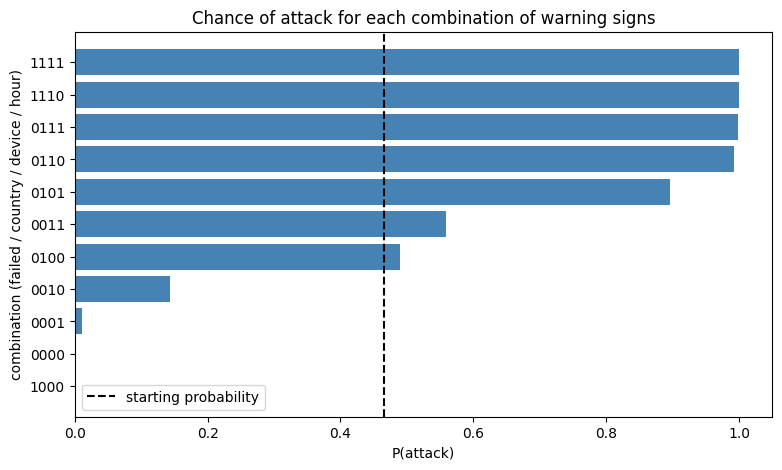

Read the labels like this: 1011 means
  failed_attempt = 1, unusual_country = 0, new_device = 1, odd_hour = 1


In [ ]:
# show the same thing as a chart
chart_data = combinations[combinations["how_many_logins"] >= 20].copy()
chart_data["combination"] = (chart_data[warning_signs].astype(str)
                             .agg("".join, axis=1))

plt.figure(figsize=(9, 5))
plt.barh(chart_data["combination"], chart_data["P(attack)"], color="steelblue")
plt.axvline(prior, color="black", linestyle="--", label="starting probability")
plt.xlabel("P(attack)")
plt.ylabel("combination (failed / country / device / hour)")
plt.title("Chance of attack for each combination of warning signs")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

print("Read the labels like this: 1011 means")
print("  failed_attempt = 1, unusual_country = 0, new_device = 1, odd_hour = 1")

In [ ]:
def check_login(failed_attempt=0, unusual_country=0, new_device=0, odd_hour=0):
    p, how_many = chance_of_attack(failed_attempt=failed_attempt,
                                   unusual_country=unusual_country,
                                   new_device=new_device,
                                   odd_hour=odd_hour)

    if how_many == 0:
        print("We have never seen a login like this, so we cannot say.")
        return

    if p < 0.20:
        action = "ALLOW the login"
    elif p < 0.80:
        action = "ASK FOR OTP / extra verification"
    else:
        action = "BLOCK the login"

    print("Chance this login is an attack:", round(p * 100, 1), "%")
    print("Based on", how_many, "similar logins in the dataset")
    print("Suggested action:", action)


print("EXAMPLE 1 - normal looking login, nothing unusual")
check_login()

print()
print("EXAMPLE 2 - correct password, usual country, but a new device at 2 AM")
check_login(new_device=1, odd_hour=1)

print()
print("EXAMPLE 3 - failed passwords, foreign country, new device, 3 AM")
check_login(failed_attempt=1, unusual_country=1, new_device=1, odd_hour=1)

EXAMPLE 1 - normal looking login, nothing unusual
Chance this login is an attack: 0.1 %
Based on 51728 similar logins in the dataset
Suggested action: ALLOW the login

EXAMPLE 2 - correct password, usual country, but a new device at 2 AM
Chance this login is an attack: 55.9 %
Based on 1611 similar logins in the dataset
Suggested action: ASK FOR OTP / extra verification

EXAMPLE 3 - failed passwords, foreign country, new device, 3 AM
Chance this login is an attack: 100.0 %
Based on 26 similar logins in the dataset
Suggested action: BLOCK the login


In [ ]:
check_login(failed_attempt=0,
            unusual_country=0,
            new_device=1,
            odd_hour=0)

Chance this login is an attack: 14.4 %
Based on 5167 similar logins in the dataset
Suggested action: ALLOW the login


In [ ]:
table.to_csv("unit1_single_warning_signs.csv", index=False)
combinations.to_csv("unit1_all_combinations.csv", index=False)

print("Saved: unit1_single_warning_signs.csv")
print("Saved: unit1_all_combinations.csv")

Saved: unit1_single_warning_signs.csv
Saved: unit1_all_combinations.csv


## What we found

1. Without any information, the chance a login is an attack is about **47%** (this dataset has a lot of attacks in it on purpose).
2. **Each warning sign on its own raises that number.** Unusual country raises it the most.
3. **The absence of a warning sign lowers it**, which matters just as much.
4. **Together the warning signs are far stronger than any single one.** A login with all 4 signs is almost certainly an attack; a login with none is almost certainly fine.
5. Bayes' theorem gives the same answer as counting rows, which is why the formula is useful when we cannot count directly.

## Reference

Dataset: NSL-KDD, Canadian Institute for Cybersecurity — https://www.unb.ca/cic/datasets/nsl.html
Login statistics: Wiefling, Jørgensen, Thunem, Lo Iacono (2022), *Pump Up Password Security!*, ACM TOPS.